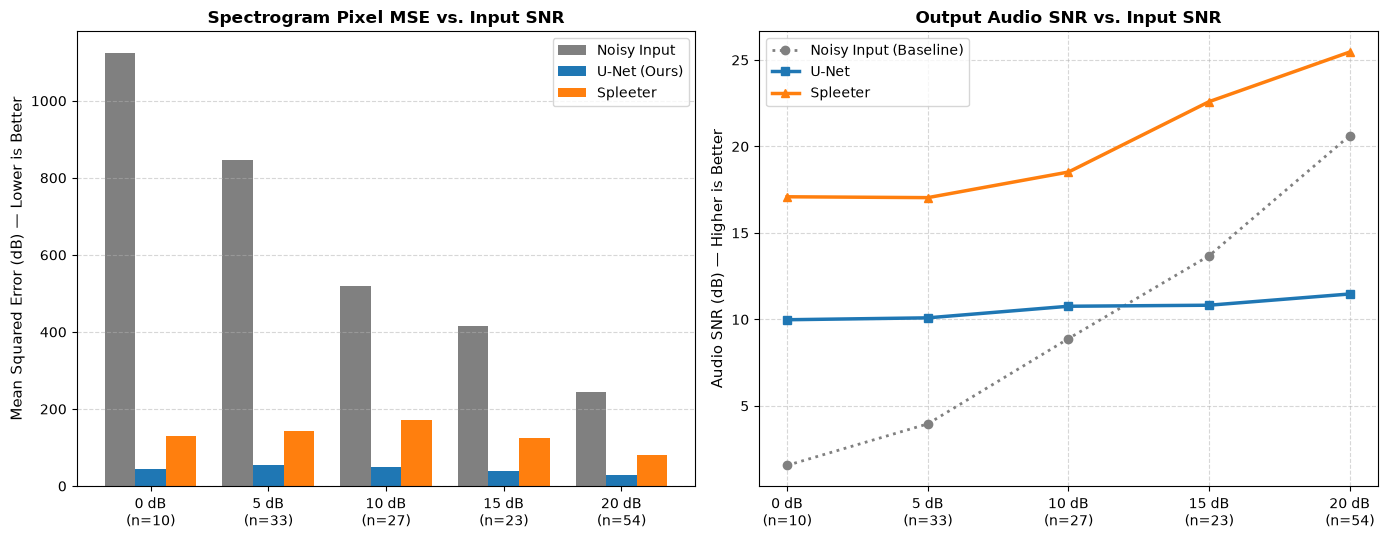

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Data Setup
snr_bins = ["0 dB\n(n=10)", "5 dB\n(n=33)", "10 dB\n(n=27)", "15 dB\n(n=23)", "20 dB\n(n=54)"]
x = np.arange(len(snr_bins))
width = 0.26

# Metrics
noisy_mse = [1124.18, 845.58, 519.37, 416.21, 245.42]
unet_mse  = [45.54, 54.64, 49.26, 40.02, 28.31]
spleeter_mse = [131.05, 144.16, 171.00, 125.81, 80.94]

noisy_snr = [1.56, 3.96, 8.89, 13.68, 20.63]
unet_snr  = [9.98, 10.09, 10.76, 10.82, 11.47]
spleeter_snr = [17.09, 17.04, 18.52, 22.59, 25.46]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Plot 1: Spectrogram MSE (Image Domain)
rects1 = ax1.bar(x - width, noisy_mse, width, label="Noisy Input", color="#808080")
rects2 = ax1.bar(x, unet_mse, width, label="U-Net (Ours)", color="#1f77b4")
rects3 = ax1.bar(x + width, spleeter_mse, width, label="Spleeter", color="#ff7f0e")

ax1.set_ylabel("Mean Squared Error (dB) — Lower is Better", fontsize=11)
ax1.set_title("Spectrogram Pixel MSE vs. Input SNR", fontsize=12, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(snr_bins)
ax1.legend(frameon=True)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# Plot 2: Audio SNR (Time Domain)
ax2.plot(x, noisy_snr, marker="o", linewidth=2, label="Noisy Input (Baseline)", color="#808080", linestyle=":")
ax2.plot(x, unet_snr, marker="s", linewidth=2.5, label="U-Net", color="#1f77b4")
ax2.plot(x, spleeter_snr, marker="^", linewidth=2.5, label="Spleeter", color="#ff7f0e")

ax2.set_ylabel("Audio SNR (dB) — Higher is Better", fontsize=11)
ax2.set_title("Output Audio SNR vs. Input SNR", fontsize=12, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(snr_bins)
ax2.legend(frameon=True)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()